# Kestrel · Milestone 1 · Notebook 01 — Read every source, profile it, say what is wrong

Nine files, four formats, three clocks. Before anything is fixed, this notebook reads every batch file **in its own format** and profiles it: row counts, null rates, cardinalities, distributions, timestamp ranges — and, for every problem, *how it was detected*. Nothing is repaired here. Notebook 02 does the cleaning, by calling the functions in `kestrel_m1/`.

**Rules for this notebook**

1. **Bronze is never edited.** Every frame here is exactly as exported (strings stay strings). Only the two provenance columns `source_file` / `source_line` are added.
2. **Say what is wrong before fixing anything.** Each section ends with the findings it produced; the decisions are in Notebook 02 and in `docs/DATA_QUALITY_FINDINGS.md`.
3. **Evidence, not guesses.** Clock conventions are established from records that can be lined up with other sources.

| Section | File | Format | Read with |
|---|---|---|---|
| 1 | `agent_activity.parquet` | Parquet | pyarrow, schema checked against the Dataset Description |
| 2 | `tenants.csv`, `agents.csv`, `tools.csv`, `model_pricing.csv` | CSV | pandas, every column as text |
| 3 | `sandbox_policies.json` | nested JSON | `json` + `json_normalize`, lists exploded |
| 4 | `network_flows.csv` | CSV | pandas |
| 5 | `sandbox_audit.log` | syslog text | regex, line by line |
| 6 | `siem_alerts.json` | nested JSON envelope | `json` + `json_normalize` |
| 7 | — | — | clock conventions: summary of how each one was established |
| 8 | — | — | the full list of problems found |


In [1]:
import sys, json, re, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=DeprecationWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# the notebook lives in M1/notebooks; the reusable module in M1/kestrel_m1
M1 = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "kestrel_m1").exists())
sys.path.insert(0, str(M1))

from kestrel_m1 import config as C
from kestrel_m1 import readers, profiling, timestamps
from kestrel_m1.profiling import profile, timestamp_shapes, enum_check, fill_pattern_by_type, numeric_ranges

pd.set_option("display.max_columns", 60); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80)
RAW = C.resolve_raw_dir()
print("telemetry pack:", RAW)

telemetry pack: /Users/mohamedmahmoud/Downloads/Nada /kestrel-telemetry-pack-v1


In [2]:
inventory = []
for key, fname in C.FILES.items():
    p = RAW / fname
    rows = None
    if fname.endswith(".csv") or fname.endswith(".log"):
        with open(p, encoding="utf-8") as f:
            rows = sum(1 for _ in f) - (1 if fname.endswith(".csv") else 0)
    inventory.append({"file": fname, "format": fname.rsplit(".", 1)[1], "size_MB": round(p.stat().st_size / 1e6, 2), "lines_or_rows": rows})
pd.DataFrame(inventory)

,file,format,size_MB,lines_or_rows
0,tenants.csv,csv,0.00,6.0
1,agents.csv,csv,0.00,22.0
2,tools.csv,csv,0.00,18.0
3,model_pricing.csv,csv,0.00,5.0
4,sandbox_policies.json,json,0.01,NaN
5,agent_activity.parquet,parquet,33.27,NaN
6,network_flows.csv,csv,5.60,42392.0
7,sandbox_audit.log,log,34.70,184005.0
8,siem_alerts.json,json,1.65,NaN


`stream_events.json` and `incident_labels.csv` are also in the pack but are **not used until Milestone 2** (the labels are held-out ground truth and are never read in this milestone).

## 1 · `agent_activity.parquet` — the main input

### 1.1 Schema check, then bronze read

The Dataset Description (3.5) promises 30 columns, counts typed `int64`, and the three timestamp columns as **raw strings**. We check the Arrow schema against that contract *before* loading anything.

In [3]:
schema_report = readers.check_parquet_schema(RAW / C.FILES["agent_activity"])
pd.Series({k: v for k, v in schema_report.items() if k != "type_mismatches"}).to_frame("value")

,value
num_rows,937752
num_row_groups,1
compression,ZSTD
created_by,parquet-cpp-arrow version 25.0.1
missing_columns,[]
unexpected_columns,[]
ok,True


In [4]:
activity, _ = readers.read_activity_bronze(RAW / C.FILES["agent_activity"])
print(activity.shape)
activity.head(3)

(937752, 32)


,source_file,source_line,event_id,event_time,ingest_time,sequence_number,event_type,session_id,tenant_id,agent_id,release_version,sandbox_instance_id,status,latency_ms,turn_index,model_id,content_source,stated_goal,injection_indicators,input_tokens,output_tokens,finish_reason,tool_id,tool_version,finished_at,retry_number,error_class,target_resource,bytes_out,task_id,task_category,expected_tool_categories
0,agent_activity.parquet,1,ev_0223988,2026-02-26T12:12:16.922Z,2026-02-26T12:12:17.788Z,1,session.start,ss_024101,tn_002,ag_019,0.9.0,sbx_01d6,ok,<NA>,<NA>,None,None,None,None,<NA>,<NA>,None,None,None,None,<NA>,None,None,<NA>,tk_024101,data_query,database|retrieval|filesystem
1,agent_activity.parquet,2,ev_0773073,2026-03-03T19:00:17.821Z,2026-03-03T19:00:18.834Z,11,tool.call,ss_083269,tn_001,ag_004,3.0.2,sbx_01a0,success,1478,<NA>,None,None,None,None,<NA>,<NA>,None,tl_sql_query,1.5.0,2026-03-03T19:00:19.299Z,0,None,warehouse.tickets,<NA>,None,None,None
2,agent_activity.parquet,3,ev_0651819,2026-02-04T04:07:09.520Z,2026-02-04T04:07:10.119Z,1,session.start,ss_070233,tn_005,ag_031,0.3.0,sbx_0201,ok,<NA>,<NA>,None,None,None,None,<NA>,<NA>,None,None,None,None,<NA>,None,None,<NA>,tk_070233,incident_response,shell|database|filesystem


The file keeps its promise at the schema level: 30 columns, `zstd`, one row group of 937,752 rows (the overview said ~940k). Integer columns are read as pandas nullable `Int64`, so a null does not silently turn the column into floats. Now the profile.

In [5]:
prof = profile(activity)
prof

,dtype,python_types,missing,missing_rate,distinct,min,max,most_common
event_id,object,str,0,0.0000,930325,ev_0000001,ev_0939831,"{'ev_0862350': 2, 'ev_0242882': 2, 'ev_0447729': 2}"
event_time,object,str,0,0.0000,929319,01/02/2026 03:44:57,not-a-time,"{'2026-02-30T10:00:00Z': 366, 'not-a-time': 347, '2026-02-17T08:58:08.056Z': 3}"
ingest_time,object,str,0,0.0000,937393,2026-01-31T00:00:35.885Z,2026-04-01T00:16:52.265Z,"{'2026-03-25T13:17:51.557Z': 2, '2026-02-22T15:13:45.025Z': 2, '2026-03-13T2..."
sequence_number,Int64,int,302,0.0003,18,1,18,"{2: 101197, 4: 101179, 1: 101141}"
event_type,object,str,0,0.0000,7,agent.telepathy,tool.call,"{'llm.turn': 413526, 'tool.call': 323750, 'session.start': 101141}"
session_id,object,str,0,0.0000,100533,ss_000001,ss_900332,"{'ss_021442': 19, 'ss_092744': 19, 'ss_015917': 18}"
tenant_id,object,str,0,0.0000,6,tn_001,tn_777,"{'tn_001': 578386, 'tn_003': 124284, 'tn_002': 122522}"
agent_id,object,str,0,0.0000,16,ag_001,ag_999,"{'ag_004': 443889, 'ag_001': 55966, 'ag_019': 50419}"
release_version,object,str,0,0.0000,18,0.3.0,v2.3.1,"{'3.0.2': 299235, '3.0.1': 144654, '1.0.0': 138339}"
sandbox_instance_id,object,str,0,0.0000,43,sbx_0000,sbx_0215,"{'sbx_01a0': 149405, 'sbx_01ad': 147518, 'sbx_01ba': 146966}"


**What the profile shows (read top-down):**

- `event_id` has 930,325 distinct values for 937,752 rows → **7,427 rows repeat an event_id** (section 1.6).
- `event_type` has **7 distinct values**; the enum has 5 (section 1.2).
- `status` has **8 distinct values** plus 738 nulls; the enum has 6 (section 1.2).
- `sequence_number` has 302 nulls although it is required on every row.
- `event_time`, `ingest_time`, `finished_at` are strings, as promised; their *min/max* are suspicious (`1769990758574`, `not-a-time`) → several formats in one column (section 1.4).
- `tenant_id` has 6 distinct values but `tenants.csv` has 6 rows one of which (tn_004) carries no traffic → an unknown tenant is in here (section 1.7).
- `release_version` has 7 distinct values for 5 agents' worth of versions… with a `v` prefix on some (section 1.7).
- `latency_ms`, `input_tokens`, `retry_number` have **negative minima** (section 1.8).
- `output_tokens` has more nulls than `input_tokens` → missing token counts on some turns (section 1.8).

### 1.2 Enums: `event_type` and `status`

In [6]:
display(enum_check(activity["event_type"], C.EVENT_TYPES))
display(enum_check(activity["status"], C.STATUS_LIFECYCLE_TURN + C.STATUS_TOOL))
pd.crosstab(activity["event_type"], activity["status"].fillna("<null>"))

,rows,in_enum
event_type,,
llm.turn,413526,True
tool.call,323750,True
session.start,101141,True
session.end,91636,True
session.error,7397,True
agent.telepathy,152,False
llm.thought,150,False


,rows,in_enum
status,,
ok,606205,True
success,293218,True
failure,14762,True
timeout,10721,True
error,7397,True
denied,4551,True
None,738,False
succeeded,160,False


status,<null>,denied,error,failure,ok,succeeded,success,timeout
event_type,,,,,,,,
agent.telepathy,0,0,0,0,152,0,0,0
llm.thought,0,0,0,0,150,0,0,0
llm.turn,400,0,0,0,413126,0,0,0
session.end,0,0,0,0,91636,0,0,0
session.error,0,0,7397,0,0,0,0,0
session.start,0,0,0,0,101141,0,0,0
tool.call,338,4551,0,14762,0,160,293218,10721


- `agent.telepathy` (152 rows) and `llm.thought` (150 rows) are **not in the event-type enum**; they are also the only rows with a null `sequence_number`.
- `succeeded` (160 tool calls) is a **spelling variant** of `success` — and 17 of those rows also carry an `error_class`, which a success should not.
- `status` is **null on 400 `llm.turn` and 338 `tool.call` rows**. `status` is required on every row.

### 1.3 Which columns each event type fills

The row's `event_type` decides which columns are filled. A column that is filled on 99.9% rather than 100% of its type hides rows with the type-specific fields missing.

In [7]:
fill_pattern_by_type(activity, "event_type")

event_type,agent.telepathy,llm.thought,llm.turn,session.end,session.error,session.start,tool.call
event_id,1.0,1.0,1.000,1.000,1.0,1.000,1.000
event_time,1.0,1.0,1.000,1.000,1.0,1.000,1.000
ingest_time,1.0,1.0,1.000,1.000,1.0,1.000,1.000
sequence_number,0.0,0.0,1.000,1.000,1.0,1.000,1.000
session_id,1.0,1.0,1.000,1.000,1.0,1.000,1.000
tenant_id,1.0,1.0,1.000,1.000,1.0,1.000,1.000
agent_id,1.0,1.0,1.000,1.000,1.0,1.000,1.000
release_version,1.0,1.0,1.000,1.000,1.0,1.000,1.000
sandbox_instance_id,1.0,1.0,1.000,1.000,1.0,1.000,1.000
status,1.0,1.0,0.999,1.000,1.0,1.000,0.999


In [8]:
turns = activity[activity.event_type == "llm.turn"]; tools_ = activity[activity.event_type == "tool.call"]; starts = activity[activity.event_type == "session.start"]
hollow = pd.DataFrame({
    "llm.turn with null model_id": [turns.model_id.isna().sum()],
    "tool.call with null tool_id": [tools_.tool_id.isna().sum()],
    "session.start with null task_id": [starts.task_id.isna().sum()],
    "terminal rows with null latency_ms": [activity[activity.event_type.isin(C.TERMINAL_TYPES)].latency_ms.isna().sum()],
}).T.rename(columns={0: "rows"})
display(hollow)
print("agents on the hollow llm.turn rows:", turns[turns.model_id.isna()][["agent_id", "release_version", "sandbox_instance_id"]].drop_duplicates().values.tolist())

,rows
llm.turn with null model_id,333
tool.call with null tool_id,333
session.start with null task_id,333
terminal rows with null latency_ms,333


agents on the hollow llm.turn rows: [['ag_321', '9.9.9', 'sbx_0000'], ['ag_999', '9.9.9', 'sbx_0000']]


333 rows of each type carry **none** of their type-specific fields. They all belong to two agents that do not exist in `agents.csv` (`ag_999`, `ag_321`, version `9.9.9`, sandbox instance `sbx_0000`): 333 whole sessions of a non-existent agent. Section 1.6 confirms it.

### 1.4 Timestamps: five shapes in one column

Replace every digit with `9` and count the shapes.

In [9]:
display(timestamp_shapes(activity["event_time"]))
display(timestamp_shapes(activity["ingest_time"]))
timestamp_shapes(activity["finished_at"].dropna())

,rows,share,examples
event_time,,,
9999-99-99T99:99:99.999Z,922618,0.98386,"[2026-02-26T12:12:16.922Z, 2026-03-03T19:00:17.821Z]"
9999999999999,14029,0.01496,"[1772435438897, 1774045070052]"
99/99/9999 99:99:99,392,0.00042,"[28/02/2026 11:24:43, 29/03/2026 16:48:12]"
9999-99-99T99:99:99Z,366,0.00039,"[2026-02-30T10:00:00Z, 2026-02-30T10:00:00Z]"
not-a-time,347,0.00037,"[not-a-time, not-a-time]"


,rows,share,examples
ingest_time,,,
9999-99-99T99:99:99.999Z,937752,1.0,"[2026-02-26T12:12:17.788Z, 2026-03-03T19:00:18.834Z]"


,rows,share,examples
finished_at,,,
9999-99-99T99:99:99.999Z,323417,1.0,"[2026-03-03T19:00:19.299Z, 2026-02-01T07:18:33.258Z]"


`ingest_time` and `finished_at` are clean ISO-8601 UTC. `event_time` arrives in **five shapes**:

| shape | rows | what it is |
|---|---|---|
| `9999-99-99T99:99:99.999Z` | 922,618 | ISO-8601 UTC, as promised |
| `9999999999999` | 14,029 | 13 digits: Unix epoch **milliseconds** — but in which zone? |
| `99/99/9999 99:99:99` | 392 | `dd/mm` or `mm/dd`? no offset at all |
| `9999-99-99T99:99:99Z` | 366 | ISO-looking but every one is `2026-02-30`: **not a calendar date** |
| `not-a-time` | 347 | garbage |

Two questions must be answered **from the data**, not guessed: the epoch rows' zone and the slash rows' day order and offset. `ingest_time` on the same row is trustworthy UTC, and lateness (`ingest − event`) is 0.3–1.5 s on 99% of the ISO rows — so a correct interpretation must reproduce that distribution.

In [10]:
s = activity["event_time"].astype("string")
ingest = pd.to_datetime(activity["ingest_time"], format="ISO8601", utc=True)
iso = s.str.fullmatch(r"\d{4}-\d{2}-\d{2}T\d{2}:\d{2}:\d{2}\.\d{3}Z").fillna(False)
epoch = s.str.fullmatch(r"\d{13}").fillna(False)
dmy = s.str.fullmatch(r"\d{2}/\d{2}/\d{4} \d{2}:\d{2}:\d{2}").fillna(False)

lat_iso = (ingest[iso] - pd.to_datetime(s[iso], format="ISO8601", utc=True)).dt.total_seconds()
lat_epoch = (ingest[epoch] - pd.to_datetime(s[epoch].astype("int64"), unit="ms", utc=True)).dt.total_seconds()
pd.DataFrame({"ISO rows": lat_iso.describe(percentiles=[.5, .99]), "epoch-ms rows read as UTC": lat_epoch.describe(percentiles=[.5, .99])}).round(3)

,ISO rows,epoch-ms rows read as UTC
count,922618.000,14029.000
mean,24.349,23.323
std,196.042,189.981
min,0.300,0.300
50%,0.915,0.916
99%,982.287,840.826
max,3279.974,2690.091


Read as **UTC milliseconds**, the epoch rows have exactly the same lateness distribution as the ISO rows (median 0.9 s). Any other zone would shift them by whole hours. → epoch rows are UTC.

In [11]:
d = s[dmy]
print("slash rows: first field > 12 on", int((d.str[:2].astype(int) > 12).sum()), "rows; second field > 12 on", int((d.str[3:5].astype(int) > 12).sum()), "rows  → day-first")
naive = pd.to_datetime(d, format="%d/%m/%Y %H:%M:%S")
timestamps.infer_naive_offset_hours(naive, ingest[dmy])

slash rows: first field > 12 on 250 rows; second field > 12 on 0 rows  → day-first


,rows,share
offset_hours_naive_minus_utc,,
0.0,390,0.9949
1.0,2,0.0051


The first field exceeds 12 on 250 rows and the second never does → **day-first**. `ingest_time − naive` rounds to **0 hours** on every row → the slash rows were written in **UTC** (not in a local zone). A second check in Notebook 02 confirms each slash row sits between its session neighbours only at offset 0.

### 1.5 Lateness: `ingest_time − event_time`

A late event is one that arrives more than 10 s after it happened (Appendix A). Delivery is at-least-once, so expect both late rows and redelivered rows.

,rows
<0,0
0-1s,534871
1-5s,380856
5-10s,56
10-60s,643
1-10min,9182
10-60min,11431
>1h,0


late (> 10 s): 21256 | negative lateness: 0 | max lateness (s): 3280.0


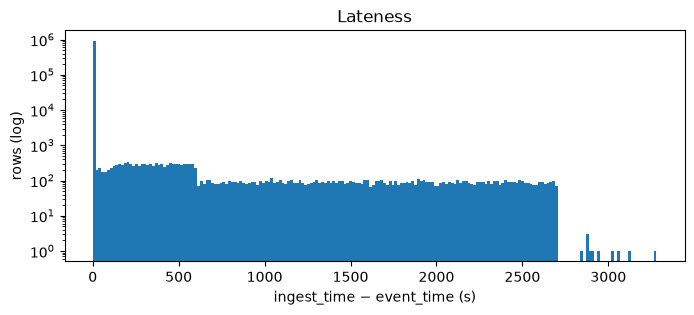

In [12]:
lat = pd.Series(np.nan, index=activity.index)
lat[iso] = lat_iso; lat[epoch] = lat_epoch; lat[dmy] = (ingest[dmy] - naive.dt.tz_localize("UTC")).dt.total_seconds()
buckets = pd.cut(lat, [-1e9, 0, 1, 5, 10, 60, 600, 3600, 1e9], labels=["<0", "0-1s", "1-5s", "5-10s", "10-60s", "1-10min", "10-60min", ">1h"])
display(buckets.value_counts().sort_index().to_frame("rows"))
print("late (> 10 s):", int((lat > 10).sum()), "| negative lateness:", int((lat < 0).sum()), "| max lateness (s):", round(lat.max(), 1))
fig, ax = plt.subplots(figsize=(8, 3)); ax.hist(lat.dropna(), bins=200, log=True); ax.set_xlabel("ingest_time − event_time (s)"); ax.set_ylabel("rows (log)"); ax.set_title("Lateness"); plt.show()

21,256 rows (2.3%) arrive late, nearly all between 1 and 55 minutes; nothing arrives before it happened. Section 1.6 shows that a third of these (7,329) are the *second copies* of duplicated events.

### 1.6 Duplicates (at-least-once delivery)

In [13]:
dup_ids = activity["event_id"].duplicated(keep=False)
d = activity[dup_ids].sort_values(["event_id", "ingest_time"])
print("rows sharing an event_id:", int(dup_ids.sum()), "| distinct repeated ids:", d.event_id.nunique(), "| copies per id:", d.groupby("event_id").size().value_counts().to_dict())
differ = {c: int(d.groupby("event_id")[c].nunique().gt(1).sum()) for c in activity.columns if c not in ("source_line",)}
print("columns that differ between the copies:", {k: v for k, v in differ.items() if v})
gap = d.groupby("event_id")["ingest_time"].agg(lambda x: (pd.to_datetime(x.max()) - pd.to_datetime(x.min())).total_seconds())
print("ingest gap between the two copies (s):", gap.describe(percentiles=[.5]).round(1).to_dict())
d.head(4)[["event_id", "event_time", "ingest_time", "event_type", "session_id", "status"]]

rows sharing an event_id: 14854 | distinct repeated ids: 7427 | copies per id: {2: 7427}
columns that differ between the copies: {'ingest_time': 7427}


ingest gap between the two copies (s): {'count': 7427.0, 'mean': 300.8, 'std': 174.1, 'min': 1.1, '50%': 300.8, 'max': 600.0}


,event_id,event_time,ingest_time,event_type,session_id,status
310508,ev_0000031,2026-03-06T08:35:31.706Z,2026-03-06T08:35:32.098Z,llm.turn,ss_000004,ok
549749,ev_0000031,2026-03-06T08:35:31.706Z,2026-03-06T08:41:04.050Z,llm.turn,ss_000004,ok
581500,ev_0000054,2026-02-24T09:49:14.087Z,2026-02-24T09:49:14.836Z,tool.call,ss_000006,success
566430,ev_0000054,2026-02-24T09:49:14.087Z,2026-02-24T09:54:41.730Z,tool.call,ss_000006,success


7,427 events arrive **exactly twice**, identical in every column except `ingest_time`: the second copy comes ~5.5 minutes later. That is a redelivery, not a different version of the event. The convention (Appendix A) is: dedup on `event_id`, **keep the copy with the earliest `ingest_time`**. Because the redelivered copies are themselves late, deduplication also removes a third of the "late" rows seen above.

### 1.7 Referential integrity, before any entity resolution

In [14]:
tenants = readers.read_csv_bronze(RAW / C.FILES["tenants"]); agents = readers.read_csv_bronze(RAW / C.FILES["agents"]); tools = readers.read_csv_bronze(RAW / C.FILES["tools"]); pricing = readers.read_csv_bronze(RAW / C.FILES["model_pricing"])
print("tenant_id in activity but not in tenants.csv:", activity.loc[~activity.tenant_id.isin(tenants.tenant_id), "tenant_id"].value_counts().to_dict())
pairs = pd.Series(list(zip(activity.agent_id, activity.release_version)))
known = set(zip(agents.agent_id, agents.release_version))
print("(agent_id, release_version) in activity but not in agents.csv:", pairs[~pairs.isin(known)].value_counts().to_dict())
print("tool_id in tool.call rows but not in tools.csv:", tools_.loc[~tools_.tool_id.isin(tools.tool_id) & tools_.tool_id.notna(), "tool_id"].value_counts().to_dict())
print("…and those values are tool *names* in tools.csv:", tools[tools.tool_name.isin(["http_get", "webfetch"])][["tool_id", "tool_version", "tool_name"]].values.tolist())
print("model_id in llm.turn rows but not in model_pricing.csv:", turns.loc[~turns.model_id.isin(pricing.model_id) & turns.model_id.notna(), "model_id"].value_counts().to_dict())
tenant_of_agent = agents.drop_duplicates("agent_id").set_index("agent_id").tenant_id
mism = activity[activity.agent_id.map(tenant_of_agent).notna() & (activity.agent_id.map(tenant_of_agent) != activity.tenant_id)]
print("rows whose tenant_id disagrees with the agent's tenant in agents.csv:", len(mism), mism.tenant_id.value_counts().to_dict())
print("sessions whose tenant_id changes mid-session:", int((activity.groupby('session_id').tenant_id.nunique() > 1).sum()), "| whose release_version changes mid-session:", int((activity.groupby('session_id').release_version.nunique() > 1).sum()))

tenant_id in activity but not in tenants.csv: {'tn_777': 736}


(agent_id, release_version) in activity but not in agents.csv: {('ag_999', '9.9.9'): 672, ('ag_321', '9.9.9'): 660, ('ag_007', 'v2.2.0'): 359}
tool_id in tool.call rows but not in tools.csv: {'http_get': 490, 'webfetch': 490}
…and those values are tool *names* in tools.csv: [['tl_web_fetch', '1.1.0', 'http_get'], ['tl_web_fetch', '1.0.0', 'webfetch']]
model_id in llm.turn rows but not in model_pricing.csv: {}


rows whose tenant_id disagrees with the agent's tenant in agents.csv: 736 {'tn_777': 736}


sessions whose tenant_id changes mid-session: 727 | whose release_version changes mid-session: 1888


Four distinct integrity problems, which need **different** treatments:

| problem | rows | nature | treatment (Notebook 02) |
|---|---|---|---|
| `tn_777` | 736 | a tenant that does not exist; the rows sit inside sessions that otherwise belong to a real tenant | reject `UNKNOWN_TENANT_ID` |
| `(ag_999, 9.9.9)`, `(ag_321, 9.9.9)` | 1,332 | agents that do not exist (whole sessions, hollow rows, instance `sbx_0000`) | reject `UNKNOWN_AGENT_ID` |
| `(ag_007, v2.3.1)`, `(ag_007, v2.2.0)` | 2,351 | the **same** agent versions spelled with a leading `v` | entity resolution: `v2.3.1 → 2.3.1` |
| `tool_id = http_get / webfetch` | 980 | the tool's **name** used where its id belongs | entity resolution: name → `tl_web_fetch` |

### 1.8 Numeric ranges

In [15]:
num_cols = ["sequence_number", "latency_ms", "turn_index", "input_tokens", "output_tokens", "retry_number", "bytes_out"]
display(numeric_ranges(activity, num_cols).round(1))
for c in ["latency_ms", "input_tokens", "retry_number"]:
    neg = activity[activity[c] < 0]
    print(f"{c} < 0: {len(neg)} rows, event types {neg.event_type.value_counts().to_dict()}, examples {neg[c].head(4).tolist()}")
print("llm.turn rows with a model but no output_tokens:", int((turns.model_id.notna() & turns.output_tokens.isna()).sum()), "→ the missing-token-count policy must be declared")

,count,mean,std,min,0.1%,1%,50%,99%,99.9%,max,negatives,non_numeric
sequence_number,937450.0,5.6,3.4,1.0,1.0,1.0,5.0,15.0,16.0,18.0,0,0
latency_ms,835310.0,4215.3,7068.6,-4000.0,5.0,108.0,2118.0,34185.0,55826.0,109492.0,411,0
turn_index,413193.0,1.8,1.6,0.0,0.0,0.0,2.0,6.0,6.0,7.0,0,0
input_tokens,413193.0,3751.1,2547.8,-12655.0,-3341.6,490.0,3286.0,10624.0,12291.6,14576.0,830,0
output_tokens,409077.0,239.8,121.6,30.0,30.0,34.0,240.0,446.0,450.0,450.0,0,0
retry_number,323417.0,0.0,0.2,-1.0,0.0,0.0,0.0,1.0,1.0,2.0,321,0
bytes_out,43300.0,2857.5,6261.3,128.0,128.0,128.0,1401.0,41673.7,62962.5,65525.0,0,0


latency_ms < 0: 411 rows, event types {'llm.turn': 411}, examples [-1216, -3198, -2267, -1044]
input_tokens < 0: 830 rows, event types {'llm.turn': 830}, examples [-5901, -2108, -5531, -8636]
retry_number < 0: 321 rows, event types {'tool.call': 321}, examples [-1, -1, -1, -1]
llm.turn rows with a model but no output_tokens: 4116 → the missing-token-count policy must be declared


Negative latencies (411), negative input-token counts (830) and `retry_number = −1` (321) are impossible values. The true value is unknown, and the closed rejection enum has a reason for exactly this (`INVALID_NUMERIC_RANGE`). 4,116 turns have no `output_tokens`: those are kept, flagged, and excluded from token sums (**null-excluded** policy, declared in the data dictionary and tested in Notebook 02).

### 1.9 Session structure

A session should run `session.start` (sequence 1) → alternating turns and tool calls → one terminal row, with contiguous sequence numbers.

In [16]:
dd = activity.sort_values("ingest_time").drop_duplicates("event_id")  # look past the redeliveries
n_sess = dd.session_id.nunique()
has_start = set(dd.loc[dd.event_type == "session.start", "session_id"])
term = dd[dd.event_type.isin(C.TERMINAL_TYPES)].groupby("session_id").size()
seq = dd.dropna(subset=["sequence_number"]).groupby("session_id")["sequence_number"].agg(["min", "max", "count", "nunique"])
summary = pd.Series({
    "distinct sessions": n_sess,
    "sessions with no session.start (orphans)": n_sess - len(has_start),
    "orphan rows": int((~dd.session_id.isin(has_start)).sum()),
    "sessions with > 1 session.start": int((dd[dd.event_type == 'session.start'].groupby('session_id').size() > 1).sum()),
    "sessions with no terminal row": n_sess - term.index.nunique(),
    "sessions with > 1 terminal row": int((term > 1).sum()),
    "sessions with a sequence gap (max ≠ count)": int((seq['max'] != seq['count']).sum()),
    "sessions with duplicated sequence numbers": int((seq['nunique'] != seq['count']).sum()),
    "sessions whose sequence 1 is not session.start": int((dd[dd.sequence_number == 1].event_type != 'session.start').sum()),
}).to_frame("count")
display(summary)
ev = pd.to_datetime(dd.event_time, format="ISO8601", utc=True, errors="coerce")
st = dd[dd.event_type == "session.start"].drop_duplicates("session_id").set_index("session_id"); tm = dd[dd.event_type.isin(C.TERMINAL_TYPES)].drop_duplicates("session_id").set_index("session_id")
dur = (ev[tm.index.map(lambda i: tm.index.get_loc(i))].values if False else (pd.to_datetime(tm.event_time, format="ISO8601", utc=True, errors="coerce") - pd.to_datetime(st.event_time.reindex(tm.index), format="ISO8601", utc=True, errors="coerce")).dt.total_seconds())
print("derived duration (s):", dur.describe(percentiles=[.5, .95]).round(2).to_dict())
lat_s = tm.latency_ms.astype("Float64") / 1000
print("terminal latency_ms/1000 disagrees with derived duration by > 1 s:", int(((dur - lat_s.astype(float)).abs() > 1).sum()), "of", int(dur.notna().sum()), "sessions  (cross-check only)")
fa = pd.to_datetime(tools_.finished_at, format="ISO8601", utc=True, errors="coerce"); et = pd.to_datetime(tools_.event_time, format="ISO8601", utc=True, errors="coerce")
print("tool.call rows whose finished_at is BEFORE event_time:", int((fa < et).sum()))

,count
distinct sessions,100533
sessions with no session.start (orphans),200
orphan rows,200
sessions with > 1 session.start,0
sessions with no terminal row,2248
sessions with > 1 terminal row,0
sessions with a sequence gap (max ≠ count),700
sessions with duplicated sequence numbers,0
sessions whose sequence 1 is not session.start,0


derived duration (s): {'count': 95360.0, 'mean': 19.65, 'std': 10.21, 'min': 2.34, '50%': 17.61, '95%': 39.53, 'max': 109.49}
terminal latency_ms/1000 disagrees with derived duration by > 1 s: 1886 of 95360 sessions  (cross-check only)


tool.call rows whose finished_at is BEFORE event_time: 1591


- **200 orphan sessions**: one `tool.call` each, for a session that never had a `session.start` (`ss_8xxxxx`).
- **2,248 sessions never terminate** (no `session.end`/`session.error`); they are excluded from the duration and success metrics by definition.
- **700 sessions already have a sequence gap** before any cleaning; rejecting rows will create more, and that is what the trace-completeness metric measures.
- The terminal row's `latency_ms` disagrees with the derived duration on ~1.9% of sessions, and 1,591 tool calls finish before they start: `latency_ms`/`finished_at` are cross-checks, never the source of duration.

### 1.10 Where the traffic concentrates

,sessions,share
tenant_id,,
tn_001,56762,0.566
tn_003,15750,0.157
tn_002,15552,0.155
tn_005,10206,0.102
tn_006,2063,0.021


sessions
agent_id release_version          
ag_004   3.0.2               26791
         3.0.1               12968
ag_001   1.0.0                6873
ag_019   0.9.0                6200
ag_011   1.4.0                4560
ag_007   2.3.1                4374
ag_031   0.3.0                4156
ag_021   1.2.0                3893

sandbox instances: 43 | top 3 carry 0.473 of all rows


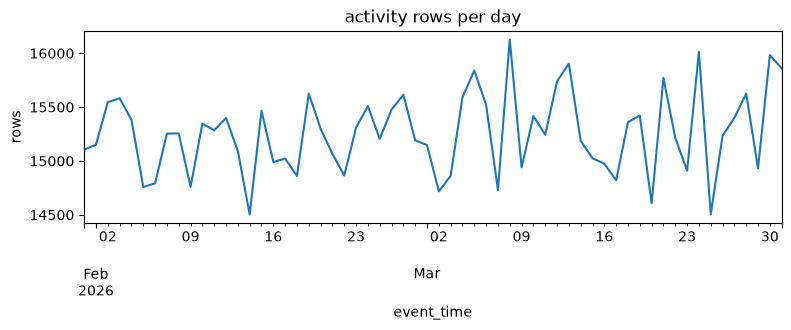

In [17]:
ss = dd[dd.event_type == "session.start"]
display(ss.groupby("tenant_id").size().rename("sessions").to_frame().assign(share=lambda x: (x.sessions / x.sessions.sum()).round(3)).sort_values("sessions", ascending=False))
display(ss.groupby(["agent_id", "release_version"]).size().rename("sessions").sort_values(ascending=False).head(8).to_frame())
print("sandbox instances:", dd.sandbox_instance_id.nunique(), "| top 3 carry", round(dd.sandbox_instance_id.value_counts().head(3).sum() / len(dd), 3), "of all rows")
daily = ev.dt.floor("D").value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 2.5)); daily.plot(ax=ax); ax.set_title("activity rows per day"); ax.set_ylabel("rows"); plt.show()

One tenant (`tn_001`) owns 56% of sessions and one agent version (`ag_004 3.0.2`) 27%; three sandbox instances carry 47% of all rows. This is the skew Milestone 2 must respond to in Spark; here it is recorded.

## 2 · Reference tables

Small enough to read whole, which is the right way to profile them.

In [18]:
display(tenants.drop(columns=["source_file"]))
display(enum_check(tenants.region, C.TENANT_REGIONS))
print("normalised-name duplicates:", tenants.tenant_name.pipe(profiling.normalise_name).duplicated(keep=False).tolist())
print("tenants with traffic:", sorted(activity.tenant_id.unique()), "| inactive tenants with traffic:", tenants[(tenants.is_active == 'false') & tenants.tenant_id.isin(activity.tenant_id)].tenant_id.tolist())

,source_line,tenant_id,tenant_name,industry,plan_tier,region,onboarded_at,is_active,security_contact
0,2,tn_001,Zephyr Logistics,logistics,growth,eu-west-1,2025-06-02T09:00:00Z,true,soc@zephyr-logistics.example
1,3,tn_002,Helios Care Group,healthcare,enterprise,us-east-1,2025-03-18T14:30:00Z,true,security@helios-care.example
2,4,tn_003,NILEBANK Ltd.,finance,enterprise,me-south-1,2024-11-11T08:15:00Z,true,ciso@nilebank.example
3,5,tn_004,nilebank,finance,enterprise,me-south-1,2024-11-11T08:15:00Z,true,ciso@nilebank.example
4,6,tn_005,Orion Retail,retail,starter,eu-central-9,2026-01-05T10:00:00Z,true,NaN
5,7,tn_006,Vega Public Works,public_sector,growth,eu-west-1,2025-09-30T11:45:00Z,false,ops@vega-pw.example


,rows,in_enum
region,,
eu-west-1,2,True
me-south-1,2,True
us-east-1,1,True
eu-central-9,1,False


normalised-name duplicates: [False, False, True, True, False, False]
tenants with traffic: ['tn_001', 'tn_002', 'tn_003', 'tn_005', 'tn_006', 'tn_777'] | inactive tenants with traffic: ['tn_006']


- `tn_003 NILEBANK Ltd.` and `tn_004 nilebank` have the **same normalised name and identical attributes** (industry, plan, region, onboarding time, contact): one tenant under two ids. Only `tn_003` has traffic. → resolve `tn_004 → tn_003`.
- `tn_005` has region `eu-central-9`, **not in the enum**, and no `security_contact`.
- `tn_006` is inactive but has traffic (2,063 sessions): expected per the description ("some inactive tenants still have historical traffic"), not a defect.

In [19]:
display(agents.drop(columns=["source_file"]).sort_values(["agent_id", "release_version"]))
print("natural key (agent_id, release_version) duplicated:", int(agents.duplicated(['agent_id', 'release_version']).sum()))
print("release_version not semver:", agents.loc[~agents.release_version.str.fullmatch(r'\d+\.\d+\.\d+'), ['agent_id', 'release_version', 'agent_name', 'autonomy_level']].values.tolist())
pol_raw = readers.read_json(RAW / C.FILES["sandbox_policies"])
print("sandbox_profile_id with no policy:", agents.loc[~agents.sandbox_profile_id.isin({p['sandbox_profile_id'] for p in pol_raw}), ['agent_id', 'release_version', 'sandbox_profile_id']].values.tolist())

,source_line,agent_id,release_version,agent_name,agent_type,model_id,tenant_id,sandbox_profile_id,owner_team,autonomy_level,max_tool_calls_per_session,launch_date,is_deprecated
2,4,ag_001,1.0.0,route-optimizer-agent,analytics,mdl_kst_lite_1,tn_001,sp_analytics_std,fleet-ops,semi_autonomous,30,2025-10-01,false
3,5,ag_002,2.1.0,support-desk-agent,support,mdl_kst_lite_1,tn_001,sp_support_std,cx-platform,supervised,10,2025-11-01,true
4,6,ag_002,2.2.0,support-desk-agent,support,mdl_kst_lite_1,tn_001,sp_support_std,cx-platform,supervised,10,2026-02-25,false
5,7,ag_003,0.5.0,code-review-agent,coding,mdl_kst_pro_1,tn_001,sp_coding_std,dev-platform,semi_autonomous,40,2025-12-01,true
6,8,ag_003,0.6.0,code-review-agent,coding,mdl_kst_pro_2,tn_001,sp_coding_std,dev-platform,semi_autonomous,40,2026-03-05,false
0,2,ag_004,3.0.1,ops-runbook-agent,ops,mdl_kst_pro_1,tn_001,sp_ops_elevated,sre,autonomous,60,2025-08-14,true
1,3,ag_004,3.0.2,ops-runbook-agent,ops,mdl_kst_pro_1,tn_001,sp_ops_elevated,sre,autonomous,60,2026-02-20,false
11,13,ag_007,2.2.0,market-research-agent,research,mdl_kst_lite_1,tn_003,sp_research_std,growth-intel,semi_autonomous,25,2025-12-01,true
12,14,ag_007,2.3.1,market-research-agent,research,mdl_kst_pro_1,tn_003,sp_research_std,growth-intel,semi_autonomous,25,2026-02-10,false
21,23,ag_007,v2.3.1,Market Research Agent,research,mdl_kst_pro_1,tn_003,sp_research_std,growth-intel,autonomous,25,2026-02-10,false


natural key (agent_id, release_version) duplicated: 0
release_version not semver: [['ag_007', 'v2.3.1', 'Market Research Agent', 'autonomous']]
sandbox_profile_id with no policy: [['ag_019', '0.9.0', 'sp_missing_profile']]


- `(ag_007, v2.3.1, "Market Research Agent", autonomous)` is the **same version** as `(ag_007, 2.3.1, "market-research-agent", semi_autonomous)` spelled differently — and the two rows disagree on autonomy. → merge into `2.3.1`, keep the conventional row's attributes, record the conflict.
- `ag_019` points at `sp_missing_profile`, which **does not exist** in `sandbox_policies.json`. Its 6,200 sessions (50k rows) can never be checked against a policy: `policy_version_applied` and `is_policy_violation` will be null for them, flagged.

In [20]:
display(tools.drop(columns=["source_file"]))
print("exact duplicate rows:", int(tools.drop(columns=['source_file', 'source_line']).duplicated().sum()), "→", tools[tools.drop(columns=['source_file', 'source_line']).duplicated(keep=False)][['source_line', 'tool_id', 'tool_version']].values.tolist())
print("tool_id with several names:", tools.groupby('tool_id').tool_name.unique().loc[lambda x: x.map(len) > 1].to_dict())
print("tool_id with several categories:", tools.groupby('tool_id').tool_category.unique().loc[lambda x: x.map(len) > 1].to_dict())

,source_line,tool_id,tool_version,tool_name,tool_category,risk_tier,requires_approval,owner_team
0,2,tl_web_fetch,1.2.0,web_fetch,retrieval,low,false,platform-tools
1,3,tl_web_fetch,1.1.0,http_get,retrieval,low,false,platform-tools
2,4,tl_web_fetch,1.0.0,webfetch,retrieval,low,false,platform-tools
3,5,tl_vector_search,2.0.1,vector_search,retrieval,low,false,platform-tools
4,6,tl_vector_search,2.0.1,vector_search,retrieval,low,false,platform-tools
5,7,tl_vector_search,2.0.0,vector_search,retrieval,low,false,platform-tools
6,8,tl_summarize,1.0.0,summarize,retrieval,low,false,platform-tools
7,9,tl_sql_query,1.5.0,sql_query,database,medium,false,data-platform
8,10,tl_sql_query,1.4.2,sql_query,database,medium,false,data-platform
9,11,tl_shell_exec,0.8.0,shell_exec,shell,critical,true,platform-tools


exact duplicate rows: 1 → [[5, 'tl_vector_search', '2.0.1'], [6, 'tl_vector_search', '2.0.1']]
tool_id with several names: {'tl_web_fetch': array(['web_fetch', 'http_get', 'webfetch'], dtype=object)}
tool_id with several categories: {'tl_code_exec': array(['code_exec', 'shell'], dtype=object)}


- `(tl_vector_search, 2.0.1)` appears **twice**, identically → one copy rejected as a duplicate on the natural key.
- `tl_web_fetch` has three names across versions (`web_fetch`, `http_get`, `webfetch`); the activity feed uses two of those names as `tool_id` → the name→id map resolves them.
- `tl_code_exec` is `shell` in 0.9.0 and `code_exec` in 0.9.1: the category of a tool should not change with its version; the canonical category is the newest version's, flagged.

In [21]:
display(pricing.drop(columns=["source_file"]))
for note in profiling.summarize_windows(pricing, "model_id", "effective_from", "effective_to"): print("-", note)
print("models with null prices:", pricing[pricing.input_price_per_1k.isna()].model_id.tolist())

,source_line,model_id,model_family,input_price_per_1k,output_price_per_1k,currency,effective_from,effective_to
0,2,mdl_kst_pro_1,kestrel-pro,0.003000,0.015000,USD,2026-01-01T00:00:00Z,NaN
1,3,mdl_kst_pro_1,kestrel-pro,0.002500,0.012000,USD,2026-03-01T00:00:00Z,NaN
2,4,mdl_kst_pro_2,kestrel-pro,0.002000,0.010000,USD,2026-03-01T00:00:00Z,NaN
3,5,mdl_kst_lite_1,kestrel-lite,0.000500,0.001500,USD,2026-01-01T00:00:00Z,NaN
4,6,mdl_kst_nano_1,kestrel-nano,NaN,NaN,USD,2026-02-01T00:00:00Z,NaN


- mdl_kst_pro_1: window starting 2026-01-01 is open-ended but a later window starts 2026-03-01 (overlap)
models with null prices: ['mdl_kst_nano_1']


- `mdl_kst_pro_1` has **two open-ended price windows**: the January price was never closed when the March price started → close it at `2026-03-01` (Type-2 repair), so "price effective at turn time" is unambiguous.
- `mdl_kst_nano_1` has **no prices**: every nano turn (29k) will have a null cost, flagged.

## 3 · `sandbox_policies.json` — flatten the nested policy versions

In [22]:
from kestrel_m1.policies import flatten_policies, policy_window_report
pol_flat, _ = readers.read_policies_bronze(RAW / C.FILES["sandbox_policies"])
dim_policy, pol_tools, pol_egress, pol_ports = flatten_policies(pol_flat)
display(dim_policy[["sandbox_profile_id", "policy_version", "valid_from_utc", "valid_to_utc", "has_network_block", "n_allowed_tools", "n_egress_allowlist", "escalation_allowed", "max_egress_mb", "max_runtime_s"]])
display(policy_window_report(dim_policy))
display(pol_egress)
print("profiles referenced by agents.csv:", sorted(agents.sandbox_profile_id.unique()))
print("profiles present in the policies:  ", sorted(dim_policy.sandbox_profile_id.unique()))

,sandbox_profile_id,policy_version,valid_from_utc,valid_to_utc,has_network_block,n_allowed_tools,n_egress_allowlist,escalation_allowed,max_egress_mb,max_runtime_s
0,sp_analytics_std,1,2026-01-01 00:00:00+00:00,2026-03-15 00:00:00+00:00,True,3,2,False,50.0,1200
1,sp_analytics_std,2,2026-03-15 00:00:00+00:00,NaT,True,4,2,False,50.0,1200
2,sp_coding_std,1,2026-01-01 00:00:00+00:00,NaT,True,4,2,False,200.0,1800
3,sp_ops_elevated,3,2025-12-01 00:00:00+00:00,2026-02-15 00:00:00+00:00,True,3,2,True,100.0,1800
4,sp_ops_elevated,4,2026-02-15 00:00:00+00:00,NaT,False,4,0,True,NaN,1800
5,sp_ops_std,1,2026-01-01 00:00:00+00:00,NaT,True,3,2,False,20.0,900
6,sp_research_std,2,2026-01-01 00:00:00+00:00,2026-02-01 00:00:00+00:00,True,2,2,False,25.0,600
7,sp_research_std,3,2026-01-25 00:00:00+00:00,NaT,True,3,3,False,50.0,900
8,sp_support_std,1,2026-01-01 00:00:00+00:00,2026-03-01 00:00:00+00:00,True,3,2,False,10.0,300
9,sp_support_std,2,2026-03-01 00:00:00+00:00,NaT,True,4,2,False,10.0,300


,sandbox_profile_id,from_version,to_version,valid_to,next_valid_from,relationship,overlap_days
0,sp_analytics_std,1,2,2026-03-15 00:00:00+00:00,2026-03-15 00:00:00+00:00,contiguous,NaN
1,sp_ops_elevated,3,4,2026-02-15 00:00:00+00:00,2026-02-15 00:00:00+00:00,contiguous,NaN
2,sp_research_std,2,3,2026-02-01 00:00:00+00:00,2026-01-25 00:00:00+00:00,overlap,7.0
3,sp_support_std,1,2,2026-03-01 00:00:00+00:00,2026-03-01 00:00:00+00:00,contiguous,NaN


,policy_sk,sandbox_profile_id,policy_version,pattern,is_wildcard
0,1,sp_analytics_std,1,api.kestrel.ai,False
1,1,sp_analytics_std,1,*.public-data.example,True
2,2,sp_analytics_std,2,api.kestrel.ai,False
3,2,sp_analytics_std,2,*.public-data.example,True
4,3,sp_coding_std,1,api.kestrel.ai,False
5,3,sp_coding_std,1,*.pkg-mirror.example,True
6,4,sp_ops_elevated,3,api.kestrel.ai,False
7,4,sp_ops_elevated,3,*.status.kestrel.ai,True
8,6,sp_ops_std,1,api.kestrel.ai,False
9,6,sp_ops_std,1,*.status.kestrel.ai,True


profiles referenced by agents.csv: ['sp_analytics_std', 'sp_coding_std', 'sp_missing_profile', 'sp_ops_elevated', 'sp_ops_std', 'sp_research_std', 'sp_support_std']
profiles present in the policies:   ['sp_analytics_std', 'sp_coding_std', 'sp_ops_elevated', 'sp_ops_std', 'sp_research_std', 'sp_support_std']


- One nested array becomes a policy dimension plus three bridge tables (allowed tools, egress allowlist patterns, denied ports). Six of the eleven allowlist entries are **wildcards** and must be glob-matched, never string-compared.
- `sp_research_std` **v2 and v3 overlap for 7 days** (v2 valid to Feb 1, v3 valid from Jan 25). Only one day of that overlap is inside the pack (Jan 31). Which version applied? Section 5 answers it from the sandbox's own log: the higher version.
- `sp_ops_elevated` **v4 has no `network` block**. By the contract that means *no egress at all* — yet section 5 shows the runtime allowing egress under it.
- `sp_missing_profile` is referenced by an agent but absent here.

## 4 · `network_flows.csv`

In [23]:
flows = readers.read_csv_bronze(RAW / C.FILES["network_flows"])
display(profile(flows))
display(timestamp_shapes(flows.flow_time))
display(pd.concat([enum_check(flows.protocol, C.FLOW_PROTOCOLS), enum_check(flows.verdict, C.FLOW_VERDICTS)]))
print("flow_id unique:", flows.flow_id.is_unique, "| exact duplicate rows:", int(flows.drop(columns=['source_file', 'source_line']).duplicated().sum()))

,dtype,python_types,missing,missing_rate,distinct,min,max,most_common
flow_id,object,str,0,0.0000,42392,nf_000001,nf_042392,"{'nf_000001': 1, 'nf_028256': 1, 'nf_028258': 1}"
session_id,object,str,0,0.0000,27858,ss_000001,ss_700083,"{'ss_069182': 7, 'ss_008392': 6, 'ss_001785': 6}"
sandbox_instance_id,object,str,0,0.0000,28,sbx_01a0,sbx_7777,"{'sbx_01fa': 2820, 'sbx_01ed': 2692, 'sbx_0207': 2631}"
flow_time,object,str,0,0.0000,42308,2026-01-31T00:10:24.419Z,2026-03-31T23:47:47.047Z,"{'2026-02-19T13:11:22.821Z': 2, '2026-02-26T15:41:19.176Z': 2, '2026-03-07T1..."
src_ip,object,str,0,0.0000,28,10.20.1.10,10.20.99.9,"{'10.20.12.11': 2820, '10.20.12.10': 2692, '10.20.12.12': 2631}"
dst_host,object,str,3514,0.0829,11,blog.industry-news.example,stats.public-data.example,"{'mail.kestrel.ai': 11342, 'research.marketwire.example': 6816, 'stats.publi..."
dst_ip,object,str,0,0.0000,63,10.20.4.10,203.0.113.47,"{'198.51.100.11': 11672, '198.51.100.22': 7012, '198.51.100.31': 6157}"
dst_port,object,str,0,0.0000,4,22,445,"{'443': 40304, '3389': 720, '22': 709}"
protocol,object,str,0,0.0000,4,https,ssh,"{'https': 40304, 'rdp': 720, 'ssh': 709}"
bytes_sent,object,str,0,0.0000,7362,1000,999,"{'512': 733, '128': 693, '256': 684}"


,rows,share,examples
flow_time,,,
9999-99-99T99:99:99.999Z,42392,1.0,"[2026-01-31T11:07:46.377Z, 2026-01-31T08:28:10.747Z]"


,rows,in_enum
https,40304,True
rdp,720,True
ssh,709,True
smb,659,True
allowed,38644,True
blocked,3321,True
logged_only,427,True


flow_id unique: True | exact duplicate rows: 0


In [24]:
print("dst_host null by protocol:", flows[flows.dst_host.isna()].protocol.value_counts().to_dict())
print("dst_host null by verdict:  ", flows[flows.dst_host.isna()].verdict.value_counts().to_dict())
print("geo_country null vs dst_host null:"); display(pd.crosstab(flows.geo_country.isna().rename("geo null"), flows.dst_host.isna().rename("dst_host null")))
print("dst_ip ranges of host-less flows:", flows[flows.dst_host.isna()].dst_ip.str.extract(r'^(\d+\.\d+)')[0].value_counts().to_dict())
print("src_ip ↔ sandbox_instance_id is 1:1:", bool((flows.groupby('src_ip').sandbox_instance_id.nunique().max() == 1) and (flows.groupby('sandbox_instance_id').src_ip.nunique().max() == 1)), "|", flows.src_ip.nunique(), "sandbox addresses")
not_in_act = ~flows.session_id.isin(set(activity.session_id))
print("flows whose session_id never appears in agent_activity:", int(not_in_act.sum()), flows.loc[not_in_act, 'session_id'].str[:6].value_counts().to_dict())
win = pd.DataFrame({"et": ev, "s": dd.session_id}).dropna().groupby("s").et.agg(["min", "max"])
j = flows.join(win, on="session_id"); ft = pd.to_datetime(j.flow_time, utc=True)
print("flows outside their session's [first, last] activity window (±5 s):", int(((ft < j['min'] - pd.Timedelta(seconds=5)) | (ft > j['max'] + pd.Timedelta(seconds=5))).sum()), "of", int(j['min'].notna().sum()), "→ flow_time is on the same UTC clock as event_time")
print("blocked flows by destination:", flows[flows.verdict == 'blocked'].dst_host.fillna('<ip only>').value_counts().to_dict())

dst_host null by protocol: {'https': 1426, 'rdp': 720, 'ssh': 709, 'smb': 659}
dst_host null by verdict:   {'blocked': 2207, 'allowed': 1151, 'logged_only': 156}
geo_country null vs dst_host null:


dst_host null,False,True
geo null,,
False,38878,1426
True,0,2088


dst_ip ranges of host-less flows: {'10.20': 2088, '198.51': 1151, '203.0': 248, '192.0': 27}
src_ip ↔ sandbox_instance_id is 1:1: True | 28 sandbox addresses
flows whose session_id never appears in agent_activity: 84 {'ss_700': 84}


flows outside their session's [first, last] activity window (±5 s): 0 of 42308 → flow_time is on the same UTC clock as event_time
blocked flows by destination: {'<ip only>': 2207, 'blog.industry-news.example': 788, 'forum.devtalk.example': 130, 'drop.exfil-host.example': 104, 'paste.unclassified.example': 92}


`network_flows.csv` is the tidiest file: ISO UTC throughout, unique ids, enums in range, and `flow_time` sits inside the session's activity window every time (same clock as `event_time`).

- `dst_host` is null on 3,514 flows: **structural**, not a defect — these are connections to bare IP addresses (lateral movement to `10.20.4.x` on 22/445/3389, and HTTPS uploads to `203.0.113.x`). `geo_country` is null exactly for the internal `10.x` destinations. Keep, flag.
- **84 flows reference sessions `ss_7000xx` that exist in no other file** → `ORPHAN_EVENT`.
- `src_ip` ↔ `sandbox_instance_id` is one-to-one: the sandbox address is a reliable correlation key for the SIEM alerts (section 6).

## 5 · `sandbox_audit.log` — syslog text, parsed with a regex

```
Jan 31 01:59:28 sbx-eu-102 kestrel-sandbox[2022]: session=ss_060876 instance=sbx_01ba decision=ALLOW action=process_spawn target=/usr/bin/journalctl reason=TOOL_ALLOWED policy_version=3
```

The header regex captures month, day, time, host, process, pid; the message is `key=value` pairs. No year, no offset.

In [25]:
audit, audit_unparsed = readers.read_syslog_bronze(RAW / C.FILES["sandbox_audit"])
print("lines:", len(audit) + len(audit_unparsed), "| header matched:", len(audit), "| header did not match:", len(audit_unparsed))
display(profile(audit.drop(columns=["raw_line"])))
kv = ["session_id", "sandbox_instance_id", "decision", "action", "target", "reason", "policy_version"]
missing_keys = audit[kv].isna()
print("lines missing at least one key=value field (truncated):", int(missing_keys.any(axis=1).sum()))
display(missing_keys.sum().to_frame("lines missing the field"))
display(audit[missing_keys.any(axis=1)][["source_line", "raw_line"]].head(5))

lines: 184005 | header matched: 184005 | header did not match: 0


,dtype,python_types,missing,missing_rate,distinct,min,max,most_common
mon,object,str,0,0.0000,4,Apr,Mar,"{'Mar': 96819, 'Feb': 84330, 'Jan': 2752}"
day,object,str,0,0.0000,31,1,9,"{'24': 6417, '27': 6345, '21': 6283}"
time,object,str,0,0.0000,69619,00:00:01,23:59:56,"{'14:34:12': 13, '14:19:09': 13, '10:16:20': 12}"
host,object,str,0,0.0000,42,sbx-eu-100,sbx-us-120,"{'sbx-eu-100': 38668, 'sbx-eu-102': 38020, 'sbx-eu-101': 37962}"
process,object,str,0,0.0000,1,kestrel-sandbox,kestrel-sandbox,{'kestrel-sandbox': 184005}
pid,object,str,0,0.0000,42,2000,3283,"{'2000': 38668, '2022': 38020, '2011': 37962}"
session_id,object,str,0,0.0000,75068,ss,ss_100000,"{'ss_079460': 10, 'ss_046668': 10, 'ss_003602': 9}"
sandbox_instance_id,object,str,77,0.0004,54,,sbx_0215,"{'sbx_01a0': 38641, 'sbx_01ba': 37999, 'sbx_01ad': 37941}"
decision,object,str,164,0.0009,7,,DENY,"{'ALLOW': 177346, 'DENY': 6478, 'AL': 5}"
action,object,str,220,0.0012,33,,socket_connect,"{'process_spawn': 91284, 'file_write': 48249, 'socket_connect': 42248}"


lines missing at least one key=value field (truncated): 524


,lines missing the field
session_id,0
sandbox_instance_id,77
decision,164
action,220
target,319
reason,492
policy_version,524


,source_line,raw_line
128,129,Jan 31 03:46:27 sbx-eu-102 kestrel-sandbox[2022]: session=ss_09
284,285,Jan 31 06:35:47 sbx-eu-100 kestrel-sandbox[2000]: session=ss_054184 instance...
357,358,Jan 31 07:46:07 sbx-eu-102 kestrel-sandbox[2022]: session=ss_015763 instance...
625,626,Jan 31 10:12:56 sbx-eu-133 kestrel-sandbox[3067]: session=ss_049581 instance...
1707,1708,Jan 31 16:14:09 sbx-me-129 kestrel-sandbox[2895]: session=ss_040738 instance...


524 lines are **cut short**: the line ends in the middle of a key or value (`decision=AL`, `target=/workspace/out/report_`, even `session=ss_09`). Whatever survives of such a line is not trustworthy (`decision=AL` is not a decision), so the whole line is rejected as `UNPARSEABLE_RECORD` and the fragment is kept in the rejects table.

In [26]:
full = audit[~missing_keys.any(axis=1)]
display(pd.concat([enum_check(full.decision, C.AUDIT_DECISIONS), enum_check(full.action, C.AUDIT_ACTIONS)]))
display(pd.crosstab(full.reason, full.decision))
print("policy_version values:", full.policy_version.value_counts().to_dict(), "  ('-' is the syslog null)")
print("exact duplicate lines (same time, host, pid and all fields):", int(full.duplicated(['mon', 'day', 'time', 'host', 'pid'] + kv).sum()))
print("months:", audit.mon.value_counts().to_dict(), "| hosts:", audit.host.nunique(), "| processes:", audit.process.unique().tolist(), "| pids:", audit.pid.nunique())

,rows,in_enum
ALLOW,177018,True
DENY,6463,True
process_spawn,91171,True
file_write,48195,True
socket_connect,42179,True
file_read,1059,True
setuid,725,True
ptrace,152,True


decision,ALLOW,DENY
reason,,
EGRESS_ALLOWED,34754,0
EGRESS_NOT_ALLOWED,0,1475
ESCALATION_FORBIDDEN,0,877
NO_NETWORK_POLICY,3705,0
PATH_IN_SCOPE,48195,0
PATH_OUT_OF_SCOPE,0,1059
PORT_DENIED,0,1820
TOOL_ALLOWED,89939,0
TOOL_NOT_ALLOWED,0,1232


policy_version values: {'4': 87473, '3': 49428, '1': 36321, '2': 7813, '-': 2446}   ('-' is the syslog null)


exact duplicate lines (same time, host, pid and all fields): 4
months: {'Mar': 96819, 'Feb': 84330, 'Jan': 2752, 'Apr': 104} | hosts: 42 | processes: ['kestrel-sandbox'] | pids: 42


On the complete lines every enum is in range. Two reasons deserve attention: `NO_NETWORK_POLICY` (3,705 **ALLOW** decisions) and `WILDCARD_MATCH_UNVERIFIED` (425 ALLOW) — the runtime *allowed* egress it could not justify from a policy. `policy_version=-` on 2,446 lines is the syslog null. Four lines are exact duplicates (redelivery). The log runs into **April**, although the pack ends on March 31 UTC: a first hint that the hosts' clocks run ahead of UTC.

### 5.1 The clock: no year, no offset — work it out

The year is the pack's (2026). For the offset, line audit decisions up with the tool calls they describe: a `process_spawn` of `/usr/bin/df` in session X *is* the `tool.call` whose `target_resource` is `/usr/bin/df` in session X. Where that pair is unique on both sides, `log_time − event_time_utc` is the host's offset.

,host,n_pairs,offset_s,p05_s,p95_s,method,whole_hours,skew_s
0,sbx-eu-100,26166,7148.8,7148.31700,7149.22900,aligned_with_tool_calls,1.99,-51.2
1,sbx-eu-101,25923,7241.2,7240.71200,7241.62400,aligned_with_tool_calls,2.01,41.2
2,sbx-eu-102,25754,7116.5,7116.00600,7116.91500,aligned_with_tool_calls,1.98,-83.5
3,sbx-eu-103,878,7248.9,7248.42200,7249.32230,aligned_with_tool_calls,2.01,48.9
4,sbx-eu-104,859,7287.4,7286.92000,7287.82010,aligned_with_tool_calls,2.02,87.4
5,sbx-eu-105,876,7153.7,7153.23550,7154.14125,aligned_with_tool_calls,1.99,-46.3
6,sbx-eu-106,793,7153.3,7152.83960,7153.85360,aligned_with_tool_calls,1.99,-46.7
7,sbx-eu-107,820,7188.0,7187.47495,7188.55310,aligned_with_tool_calls,2.00,-12.0
8,sbx-eu-108,776,7233.7,7233.13050,7234.17025,aligned_with_tool_calls,2.01,33.7
9,sbx-eu-109,1862,7178.6,7178.09405,7179.23195,aligned_with_tool_calls,1.99,-21.4


whole-hour part of every host's offset: [2.0] h | per-host skew (s) from -90.3 to 87.4 | widest p05–p95 band on any host: 1.14 s


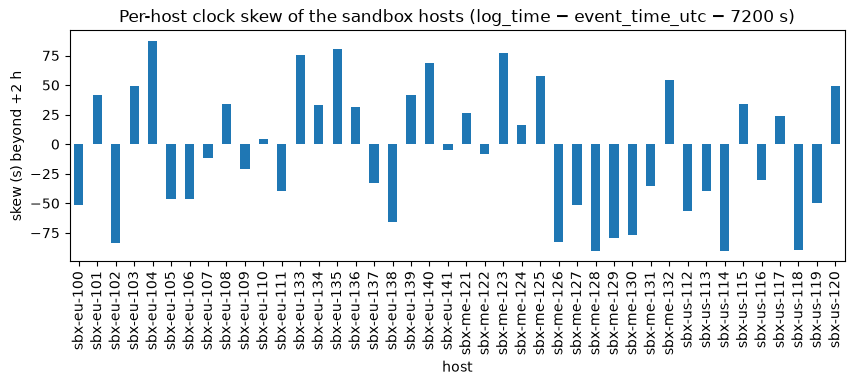

In [27]:
from kestrel_m1.timestamps import parse_syslog_naive, infer_host_clock_offsets
full = full.assign(log_time_naive=parse_syslog_naive(full.mon, full.day, full.time, C.SYSLOG_YEAR))
tc = dd[(dd.event_type == "tool.call")].assign(event_time_utc=pd.to_datetime(dd.loc[dd.event_type == "tool.call", "event_time"], format="ISO8601", utc=True, errors="coerce"))
host_off = infer_host_clock_offsets(full[["host", "session_id", "target", "log_time_naive"]], tc[["session_id", "target_resource", "event_time_utc"]])
display(host_off.head(12))
print("whole-hour part of every host's offset:", host_off.whole_hours.round().unique().tolist(), "h | per-host skew (s) from", host_off.skew_s.min(), "to", host_off.skew_s.max(), "| widest p05–p95 band on any host:", round((host_off.p95_s - host_off.p05_s).max(), 2), "s")
fig, ax = plt.subplots(figsize=(10, 3)); host_off.set_index("host").skew_s.plot.bar(ax=ax); ax.set_ylabel("skew (s) beyond +2 h"); ax.set_title("Per-host clock skew of the sandbox hosts (log_time − event_time_utc − 7200 s)"); plt.show()

In [28]:
# How much does the per-host skew matter? Share of audit lines that fall inside their session's activity window
j = full.join(win, on="session_id").dropna(subset=["min"])
def inside(offset_s):
    t = (j.log_time_naive - pd.to_timedelta(offset_s, unit="s")).dt.tz_localize("UTC")
    return round(float(((t >= j["min"] - pd.Timedelta(seconds=2)) & (t <= j["max"] + pd.Timedelta(seconds=2))).mean()), 3)
per_host = j.host.map(host_off.set_index("host").offset_s)
print("share of audit lines inside their session window:  naive −2 h exactly →", inside(7200), " |  naive − per-host offset →", inside(per_host))
print("whole-hour offset by region:", host_off.assign(region=host_off.host.str.extract(r'^sbx-([a-z]+)')[0]).groupby('region').whole_hours.agg(lambda x: x.round().mode().iloc[0]).to_dict(), " (tenant regions are eu-west-1 / us-east-1 / me-south-1, yet every host writes UTC+2)")

share of audit lines inside their session window:  naive −2 h exactly → 0.053  |  naive − per-host offset → 1.0
whole-hour offset by region: {'eu': 2.0, 'me': 2.0, 'us': 2.0}  (tenant regions are eu-west-1 / us-east-1 / me-south-1, yet every host writes UTC+2)


**Finding.** Every sandbox host — in the `eu`, `me` **and** `us` racks — writes local time at **UTC+2**, and each host's clock additionally has its own **fixed skew between −90 s and +87 s**, stable over the whole nine weeks (p05–p95 within one second on every host). Subtracting exactly two hours leaves only 5% of audit lines inside their session's window; subtracting each host's measured offset puts essentially all of them inside. The normalisation is therefore `log_time_utc = naive − offset(host)`, with the offsets published in `sandbox_host_clock_offsets.csv`.

### 5.2 What the log says about policy versions

In [29]:
agents_norm = agents.assign(release_version=agents.release_version.str.replace(r"^v", "", regex=True)).drop_duplicates(["agent_id", "release_version"])
prof_of = agents_norm.set_index(["agent_id", "release_version"]).sandbox_profile_id
sess_prof = ss.assign(rv=ss.release_version.str.replace(r"^v", "", regex=True)).set_index("session_id").apply(lambda r: prof_of.get((r.agent_id, r.rv)), axis=1)
full = full.assign(profile=full.session_id.map(sess_prof), t_utc=(full.log_time_naive - pd.to_timedelta(per_host.reindex(full.index).fillna(7200), unit="s")).dt.tz_localize("UTC"))
display(pd.crosstab(full.profile.fillna("<no profile>"), full.policy_version))
r = full[(full.profile == "sp_research_std") & (full.t_utc < pd.Timestamp("2026-02-01", tz="UTC"))]
print("sp_research_std lines inside the v2/v3 overlap day (Jan 31):", r.policy_version.value_counts().to_dict(), "→ the runtime applied the HIGHER version in the overlap")
print("NO_NETWORK_POLICY lines by profile:", full[full.reason == 'NO_NETWORK_POLICY'].profile.value_counts().to_dict(), "| earliest:", full[full.reason == 'NO_NETWORK_POLICY'].t_utc.min())
print("'-' policy_version lines by profile:", full[full.policy_version == '-'].profile.fillna('<no profile>').value_counts().to_dict())

policy_version,-,1,2,3,4
profile,,,,,
sp_analytics_std,0,3554,1792,0,0
sp_coding_std,0,13728,0,0,0
sp_missing_profile,2446,0,0,0,0
sp_ops_elevated,0,0,0,26852,87473
sp_ops_std,0,11676,0,0,0
sp_research_std,0,0,0,22576,0
sp_support_std,0,7363,6021,0,0


sp_research_std lines inside the v2/v3 overlap day (Jan 31): {'3': 346} → the runtime applied the HIGHER version in the overlap
NO_NETWORK_POLICY lines by profile: {'sp_ops_elevated': 3705} | earliest: 2026-02-15 00:41:03.200000+00:00
'-' policy_version lines by profile: {'sp_missing_profile': 2446}


- In the overlap day the sandbox applied **v3**, never v2: *latest version wins* is the rule, confirmed by the system that enforced it.
- All `NO_NETWORK_POLICY` allows are `sp_ops_elevated` from Feb 15 — exactly v4, the version with no network block. The runtime let egress through where the contract says none is allowed; by the contract, those flows are **violations**, flagged `runtime_allowed_despite_policy`.
- All `policy_version=-` lines belong to `ag_019` (`sp_missing_profile`): the runtime had no policy to apply either.

## 6 · `siem_alerts.json` — the targeted systems' view

In [30]:
siem, envelope = readers.read_siem_bronze(RAW / C.FILES["siem_alerts"])
print("envelope:", envelope)
display(profile(siem))
display(timestamp_shapes(siem.detected_at))
off = siem.detected_at.str.extract(r"([+-]\d{2}:\d{2}|Z)$")[0]
display(pd.crosstab(siem.source_system, off.rename("detected_at offset")))
print("alert_id unique:", siem.alert_id.is_unique, "| severity enum ok:", siem.severity.isin(C.SIEM_SEVERITIES).all(), "| confidence in [0,1]:", siem.confidence.between(0, 1).all())
print("source_ip prefixes:", siem.source_ip.str.extract(r'^(\d+\.\d+)')[0].value_counts().to_dict(), "| sandbox addresses are 10.20.x.x")
print("alerts whose source_ip is a sandbox address:", int(siem.source_ip.isin(set(flows.src_ip)).sum()), "of", len(siem), "| by source_system:", siem.assign(sb=siem.source_ip.isin(set(flows.src_ip))).groupby('source_system').sb.mean().round(2).to_dict())

envelope: {'generated_at': '2026-04-01T02:00:00+02:00', 'source': 'corp-siem-export-v2', 'n_alerts': 3754}


,dtype,python_types,missing,missing_rate,distinct,min,max,most_common
alert_id,object,str,0,0.0,3754,al_00001,al_03754,"{'al_00001': 1, 'al_02507': 1, 'al_02495': 1}"
source_system,object,str,0,0.0,3,cloud-ids,egress-proxy,"{'corp-siem': 1912, 'cloud-ids': 1251, 'egress-proxy': 591}"
severity,object,str,0,0.0,4,critical,medium,"{'high': 1573, 'medium': 962, 'low': 728}"
detected_at,object,str,0,0.0,3730,2026-01-30T20:55:41-05:00,2026-04-01T01:44:15+02:00,"{'2026-03-18T19:24:47+02:00': 2, '2026-03-20T01:12:14+02:00': 2, '2026-03-18..."
source_ip,object,str,0,0.0,975,10.20.12.10,10.44.9.99,"{'10.20.8.10': 237, '10.20.8.12': 221, '10.20.8.11': 209}"
rule,object,str,0,0.0,9,internal_port_sweep,unclassified_destination_upload,"{'rdp_lateral_attempt': 548, 'internal_ssh_attempt': 526, 'lateral_movement_..."
confidence,float64,float,0,0.0,76,0.2,0.95,"{0.49: 81, 0.62: 79, 0.57: 75}"
destination.host,object,str,0,0.0,56,10.20.4.10,203.0.113.47,"{'203.0.113.45': 168, '203.0.113.47': 166, '203.0.113.46': 157}"
destination.port,int64,int,0,0.0,4,22,3389,"{22: 1074, 3389: 1073, 445: 1016}"
technique.id,object,str,0,0.0,6,T1021.001,T1071.001,"{'T1021.001': 962, 'T1021.004': 957, 'T1021.002': 905}"


,rows,share,examples
detected_at,,,
9999-99-99T99:99:99+99:99,2503,0.66676,"[2026-01-31T04:19:25+03:00, 2026-01-31T07:00:10+02:00]"
9999-99-99T99:99:99-99:99,1251,0.33324,"[2026-01-30T20:55:41-05:00, 2026-01-30T22:02:59-05:00]"


detected_at offset,+02:00,+03:00,-05:00
source_system,,,
cloud-ids,0,0,1251
corp-siem,1912,0,0
egress-proxy,0,591,0


alert_id unique: True | severity enum ok: True | confidence in [0,1]: True
source_ip prefixes: {'10.20': 2503, '10.44': 1251} | sandbox addresses are 10.20.x.x
alerts whose source_ip is a sandbox address: 2503 of 3754 | by source_system: {'cloud-ids': 0.0, 'corp-siem': 1.0, 'egress-proxy': 1.0}


- Three source systems, **three fixed offsets**: `corp-siem` +02:00, `egress-proxy` +03:00, `cloud-ids` −05:00. All carry the offset explicitly, so parsing to UTC is mechanical — but anything that compared the raw strings would be hours off.
- `generated_at` in the envelope is `2026-04-01T02:00:00+02:00` = midnight UTC, the end of the batch window.
- **1,251 alerts (all `cloud-ids`) come from `10.44.x.x` sources that are not sandbox addresses**: activity outside the platform. They are genuinely unmatchable and must not be forced onto a session.

### 6.1 How far is each alert from the flow it describes?

Join on `(source_ip, destination.host = dst_ip, destination.port = dst_port)` and look at `flow_time − detected_at` for the nearest flow.

alerts with at least one (src, dst, port) candidate: 2503 | the alert comes AFTER its flow on 2498 of them


,alerts
delta_s,
≤5s,287
5-10,296
10-30,1087
30-60,766
60-120,0
120-150,0
150-300,44
300-600,23
>600,0


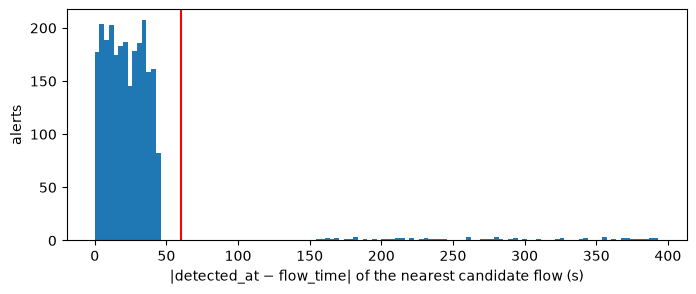

,tolerance_s,matched,ambiguous,unmatched
0,5,285,2,3467
1,10,579,4,3171
2,30,1654,16,2084
3,60,2409,27,1318
4,120,2409,27,1318
5,300,2453,27,1274
6,600,2475,28,1251


In [31]:
from kestrel_m1.correlation import correlation_sweep
sa = siem.assign(detected_at_utc=pd.to_datetime(siem.detected_at, format="ISO8601", utc=True)).rename(columns={"destination.host": "destination_host", "destination.port": "destination_port", "technique.id": "technique_id"})
fl = flows.assign(flow_time_utc=pd.to_datetime(flows.flow_time, utc=True))
cand = sa.merge(fl[["flow_id", "session_id", "src_ip", "dst_ip", "dst_port", "flow_time_utc"]], left_on=["source_ip", "destination_host"], right_on=["src_ip", "dst_ip"])
cand = cand[cand.destination_port.astype(str) == cand.dst_port.astype(str)]
cand["delta_s"] = (cand.flow_time_utc - cand.detected_at_utc).dt.total_seconds()
nearest = cand.loc[cand.groupby("alert_id").delta_s.apply(lambda s: s.abs().idxmin())]
print("alerts with at least one (src, dst, port) candidate:", nearest.alert_id.nunique(), "| the alert comes AFTER its flow on", int((nearest.delta_s <= 0).sum()), "of them")
display(pd.cut(nearest.delta_s.abs(), [-1, 5, 10, 30, 60, 120, 150, 300, 600, 1e9], labels=["≤5s", "5-10", "10-30", "30-60", "60-120", "120-150", "150-300", "300-600", ">600"]).value_counts().sort_index().to_frame("alerts"))
fig, ax = plt.subplots(figsize=(8, 3)); ax.hist(nearest.delta_s.abs(), bins=120); ax.axvline(60, color="red"); ax.set_xlabel("|detected_at − flow_time| of the nearest candidate flow (s)"); ax.set_ylabel("alerts"); plt.show()
display(correlation_sweep(sa, fl.assign(verdict=fl.verdict)))

97% of the matchable alerts are raised **0–60 s after** their flow; the band 60–150 s is **empty**; then 67 alerts trail their flow by 2.5–6.5 minutes. The tolerance **N = 60 s** sits in the empty gap, so it is a stable choice: 30 s would lose hundreds of true matches and 120 s would add none. Widening to 600 s would pick up the 67 slow alerts at the cost of one more ambiguous case; that alternative is reported, not used. At 60 s: **2,409 matched, 27 ambiguous, 1,318 unmatched** (1,251 external + 67 slow).

## 7 · Clock conventions: what each source does, and how we know

| source | field | what it looks like | convention established | evidence |
|---|---|---|---|---|
| `agent_activity.parquet` | `ingest_time`, `finished_at` | ISO-8601 `…Z` | UTC as written | 100% of rows parse; `Z` suffix |
| `agent_activity.parquet` | `event_time` (98.4%) | ISO-8601 `…Z` | UTC as written | lateness 0.3–1.5 s on 99% of rows |
| `agent_activity.parquet` | `event_time` (1.5%) | 13-digit integer | Unix epoch **ms, UTC** | read as UTC ms it reproduces the ISO rows' lateness distribution exactly |
| `agent_activity.parquet` | `event_time` (0.04%) | `dd/mm/yyyy HH:MM:SS` | **day-first, UTC** | first field > 12 on 250 rows, second never; `ingest − naive` = 0 h on every row; sits between session neighbours only at offset 0 |
| `agent_activity.parquet` | `event_time` (713 rows) | `2026-02-30…`, `not-a-time` | undecodable | rejected `MALFORMED_TIMESTAMP` |
| `network_flows.csv` | `flow_time` | ISO-8601 `…Z` | UTC as written | 100% parse; every flow inside its session's UTC window |
| `sandbox_audit.log` | `Mon dd HH:MM:SS` | no year, no offset | year 2026; **UTC+2 plus a per-host skew of −90…+87 s** | lined up with the tool calls each line logs; per-host offset tight to ±0.5 s and constant over 9 weeks |
| `siem_alerts.json` | `detected_at` | ISO-8601 with offset | as written: +02:00 / +03:00 / −05:00 by source system | explicit offsets; matched flows precede alerts by 0–60 s after conversion |
| `tenants.csv`, `model_pricing.csv`, `sandbox_policies.json` | various | ISO-8601 `…Z` | UTC as written | all parse |

## 8 · What is wrong — the list

Every problem below was found above, with the cell that detects it. The decision taken for each is in Notebook 02 and `docs/DATA_QUALITY_FINDINGS.md`.

In [32]:
findings = pd.DataFrame([
    ("agent_activity.parquet", "7,427 event_ids delivered twice (redelivery ~5.5 min later, identical except ingest_time)", "event_id.duplicated(); diff of the copies", "dedup on event_id, keep earliest ingest_time; copy → DUPLICATE_EVENT_ID"),
    ("agent_activity.parquet", "event_time in 5 shapes: ISO Z, epoch ms, dd/mm/yyyy naive, 2026-02-30, not-a-time", "digit-masked shape counts", "epoch=UTC ms, dd/mm=day-first UTC (both proven from ingest_time); 713 undecodable → MALFORMED_TIMESTAMP"),
    ("agent_activity.parquet", "21,256 rows late (> 10 s), up to 55 min; 7,329 of them redelivered copies", "ingest_time − event_time", "accepted and flagged late_event (batch has no watermark); counted in metric 9"),
    ("agent_activity.parquet", "event_type agent.telepathy / llm.thought (302 rows, null sequence_number)", "enum check", "INVALID_EVENT_TYPE"),
    ("agent_activity.parquet", "status null on 738 rows", "null count by type", "MISSING_REQUIRED_FIELD"),
    ("agent_activity.parquet", "status 'succeeded' (160), 17 with an error_class", "enum check", "normalised to success + flag; conflict flagged"),
    ("agent_activity.parquet", "tenant tn_777 (736 rows) inside otherwise valid sessions", "FK to tenants.csv", "UNKNOWN_TENANT_ID"),
    ("agent_activity.parquet", "agents ag_999 / ag_321 9.9.9: 333 hollow sessions", "FK to agents.csv", "UNKNOWN_AGENT_ID"),
    ("agent_activity.parquet", "release_version v2.3.1 / v2.2.0 for ag_007 (2,351 rows)", "FK + semver pattern", "entity resolution: strip v (flag release_version_alias)"),
    ("agent_activity.parquet", "tool_id = http_get / webfetch (980 rows)", "FK to tools.csv vs tool_name", "entity resolution: name → tl_web_fetch (flag)"),
    ("agent_activity.parquet", "negative latency_ms (411), input_tokens (830), retry_number −1 (321)", "min of numeric columns", "INVALID_NUMERIC_RANGE"),
    ("agent_activity.parquet", "4,116 turns without output_tokens", "null count", "kept null, flagged; null-excluded in token sums (effect shown)"),
    ("agent_activity.parquet", "200 orphan tool.calls (sessions with no start); 2,248 sessions never terminate; 700 sessions with sequence gaps", "session structure", "ORPHAN_EVENT; non-terminal sessions excluded from duration/success; gaps measured by trace completeness"),
    ("agent_activity.parquet", "finished_at before event_time on 1,591 tool calls; terminal latency ≠ derived duration on 1.9% of sessions", "cross-check", "flagged; duration always derived from event_time"),
    ("tenants.csv", "tn_003 and tn_004 are the same tenant", "normalised name + identical attributes", "tn_004 → tn_003"),
    ("tenants.csv", "tn_005 region eu-central-9 not in enum; no security_contact", "enum check / null", "kept, flagged"),
    ("agents.csv", "(ag_007, v2.3.1) duplicates (ag_007, 2.3.1) with conflicting autonomy", "normalised natural key", "merged; conflict recorded"),
    ("agents.csv", "ag_019 → sp_missing_profile has no policy", "FK to policies", "kept; policy fields null + flag no_policy_for_profile"),
    ("tools.csv", "exact duplicate row (tl_vector_search 2.0.1)", "duplicated()", "DUPLICATE_EVENT_ID"),
    ("tools.csv", "tl_web_fetch under 3 names; tl_code_exec category differs by version", "groupby tool_id", "name→id alias map; canonical category = newest, flagged"),
    ("model_pricing.csv", "mdl_kst_pro_1 two open-ended windows; mdl_kst_nano_1 no prices", "window overlap check / nulls", "close first window at 2026-03-01; nano cost null + flag"),
    ("sandbox_policies.json", "sp_research_std v2/v3 overlap 7 days", "window overlap check", "latest version wins (confirmed by audit log)"),
    ("sandbox_policies.json", "sp_ops_elevated v4 has no network block", "key-set check", "no egress allowed → all its flows are violations (runtime allowed them: flagged)"),
    ("network_flows.csv", "84 flows for sessions ss_7000xx that exist nowhere", "FK to activity sessions", "ORPHAN_EVENT"),
    ("network_flows.csv", "dst_host null (3,514), geo_country null (2,088)", "null pattern by protocol / dst_ip", "structural (IP-only destinations); kept, flagged"),
    ("sandbox_audit.log", "no year and no offset; hosts at UTC+2 with per-host skew −90…+87 s", "alignment with tool calls", "utc = naive − offset(host); offsets published"),
    ("sandbox_audit.log", "524 truncated lines; 4 exact duplicate lines; policy_version '-' on 2,446 lines", "regex key presence / duplicated()", "UNPARSEABLE_RECORD; DUPLICATE_EVENT_ID; '-' → null + flag"),
    ("sandbox_audit.log", "NO_NETWORK_POLICY / WILDCARD_MATCH_UNVERIFIED allows (4,130)", "reason × decision", "kept; risk indicator runtime_allow_unverified"),
    ("siem_alerts.json", "three offsets by source system (+02:00, +03:00, −05:00)", "offset suffix × source_system", "parsed as written"),
    ("siem_alerts.json", "1,251 alerts from 10.44.x.x (outside the platform); 67 alerts 2.5–6.5 min after their flow", "src_ip ∉ sandbox addresses; Δt histogram", "unmatched, never forced; N = 60 s declared, sweep reported"),
], columns=["file", "problem", "how detected", "decision"])
pd.set_option("display.max_colwidth", 120)
findings

,file,problem,how detected,decision
0,agent_activity.parquet,"7,427 event_ids delivered twice (redelivery ~5.5 min later, identical except ingest_time)",event_id.duplicated(); diff of the copies,"dedup on event_id, keep earliest ingest_time; copy → DUPLICATE_EVENT_ID"
1,agent_activity.parquet,"event_time in 5 shapes: ISO Z, epoch ms, dd/mm/yyyy naive, 2026-02-30, not-a-time",digit-masked shape counts,"epoch=UTC ms, dd/mm=day-first UTC (both proven from ingest_time); 713 undecodable → MALFORMED_TIMESTAMP"
2,agent_activity.parquet,"21,256 rows late (> 10 s), up to 55 min; 7,329 of them redelivered copies",ingest_time − event_time,accepted and flagged late_event (batch has no watermark); counted in metric 9
3,agent_activity.parquet,"event_type agent.telepathy / llm.thought (302 rows, null sequence_number)",enum check,INVALID_EVENT_TYPE
4,agent_activity.parquet,status null on 738 rows,null count by type,MISSING_REQUIRED_FIELD
5,agent_activity.parquet,"status 'succeeded' (160), 17 with an error_class",enum check,normalised to success + flag; conflict flagged
6,agent_activity.parquet,tenant tn_777 (736 rows) inside otherwise valid sessions,FK to tenants.csv,UNKNOWN_TENANT_ID
7,agent_activity.parquet,agents ag_999 / ag_321 9.9.9: 333 hollow sessions,FK to agents.csv,UNKNOWN_AGENT_ID
8,agent_activity.parquet,"release_version v2.3.1 / v2.2.0 for ag_007 (2,351 rows)",FK + semver pattern,entity resolution: strip v (flag release_version_alias)
9,agent_activity.parquet,tool_id = http_get / webfetch (980 rows),FK to tools.csv vs tool_name,entity resolution: name → tl_web_fetch (flag)
